Total profit : 600.0

Sale revenue : 2200.0
Ingredient cost : 1100.0
Truck cost : 500.0

--- Selected trucks (x) ---
Truck location truck22 open at coordinates [356.2811540822591, 145.63272120200335]
Truck location truck37 open at coordinates [209.35788827501537, 398.3939899833055]

--- Buildings ---
Building demand4 is served by the truck truck22
Building demand5 is served by the truck truck22
Building demand7 is served by the truck truck22
Building demand8 is served by the truck truck22
Building demand53 is served by the truck truck22
Building demand11 is served by the truck truck22
Building demand22 is served by the truck truck22
Building demand51 is served by the truck truck22
Building demand31 is served by the truck truck37
Building demand32 is served by the truck truck37
Building demand33 is served by the truck truck37
Building demand44 is served by the truck truck37
Building demand46 is served by the truck truck37
Building demand43 is served by the truck truck37
Building demand4

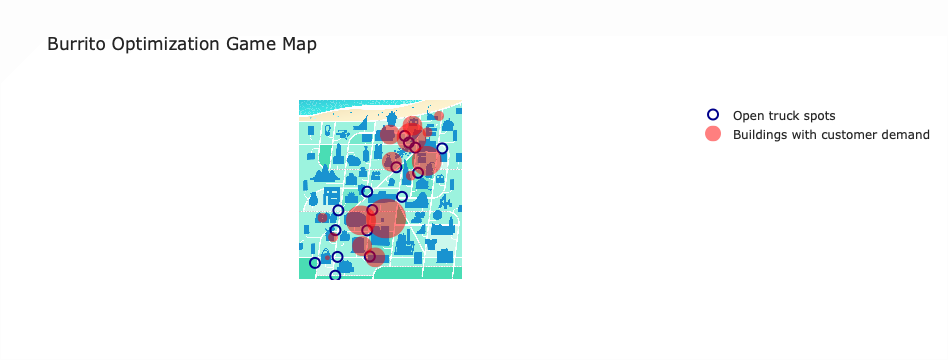

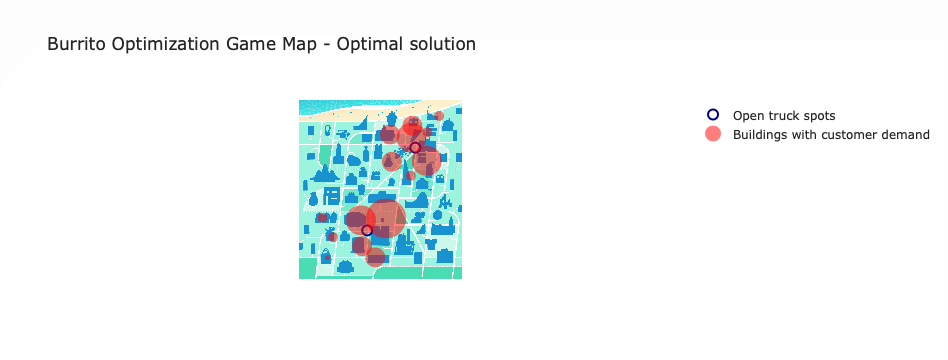

In [12]:
import pandas as pd
import gurobipy as gp
from gurobipy import GRB

model = gp.Model("burrito_game")

#Import data
round_number = 1 #Change the round number here
day_number = 1 #Change the day number here

node = pd.read_csv(f"round{round_number}-day{day_number}_demand_node_data.csv")
demand_truck_data = pd.read_csv(f"round{round_number}-day{day_number}_demand_truck_data.csv")
node_truck_data = pd.read_csv(f"round{round_number}-day{day_number}_truck_node_data.csv")
data = pd.read_csv(f"round{round_number}-day{day_number}_problem_data.csv")

#Data
r = data["burrito_price"].item()
c = data["ingredient_cost"].item()
p = data["truck_cost"].item()
T = {row["index"]: [row["x"], row["y"]] for _, row in node_truck_data.iterrows()}
B = {row["index"]: [row["x"], row["y"]] for _, row in node.iterrows()}
demand = {
    (row["demand_node_index"], row["truck_node_index"]): row["scaled_demand"]
    for _, row in demand_truck_data.iterrows()
}
pairs = gp.tuplelist([(b, t) for b in B for t in T])
truck_used = {}

#Variables
x = model.addVars(T, vtype = GRB.BINARY, name = "x")
y = model.addVars(pairs, vtype = GRB.BINARY, name = "y")

#Objective
model.setObjective( ((r - c) * y.prod(demand)) - (p*x.sum()), GRB.MAXIMIZE)

#Constraints
model.addConstrs(y.sum(b, '*') <= 1 for b in B)
model.addConstrs(y[b, t] <= x[t] for b in B for t in T)

#Model solving
model.Params.OutputFlag = 0
model.optimize()

total_revenue = sum(r * demand[b, t] * y[b, t].X for b, t in pairs if y[b, t].X > 0.5)
total_ingredient_cost = sum(c * demand[b, t] * y[b, t].X for b, t in pairs if y[b, t].X > 0.5)
total_truck_cost = sum(p * x[t].X for t in T if x[t].X > 0.5)

#Results
print(f"Total profit : {model.ObjVal}\n")
print(f"Sale revenue : {total_revenue}")
print(f"Ingredient cost : {total_ingredient_cost}")
print(f"Truck cost : {total_truck_cost}")

print("")
print("--- Selected trucks (x) ---")
for t in T:
    if x[t].X > 0.5:
        truck_used[t] = T[t]
        print(f"Truck location {t} open at coordinates {T[t]}")

print("\n--- Buildings ---")
for b, t in pairs:
    if y[b, t].X > 0.5:
        print(f"Building {b} is served by the truck {t}")

#=================================================================

#Map (possiblity)
#Data
buildings = {node["name"][i] for i in range(len(node))}
building_names = {row["index"]: row["name"] for _, row in node.iterrows()}
building_coordinates = {row["index"]: [row["x"], row["y"]] for _, row in node.iterrows()}
demand = {row["index"]: row["demand"] for _, row in node.iterrows()}
truck_coordinates = {row["index"]: [row["x"], row["y"]] for _, row in node_truck_data.iterrows()}

#Display
from util.scripts.show_map import show_map
title = "Burrito Optimization Game Map"
show_map(title, buildings, building_names, building_coordinates, demand, truck_coordinates)

#Map (optimization)
from util.scripts.show_map import show_map
title = "Burrito Optimization Game Map - Optimal solution"
show_map(title, buildings, building_names, building_coordinates, demand, truck_used)
